Pada notebook ini akan dilakukan inferensi data baru (`inference_data.jpg`) untuk mengetahui apakah koral pada gambar tersebut merupakan `healthy_corals` atau `bleached_corals`. Data di download dan disimpan dari internet lalu diambil dari local. Gambar tersebut akan di resize menjadi ukuran 200 x 250 dan rescale 1/255 sama seperti data train yang digunakan untuk pembuatan model

In [1]:
# import libraries

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
import tensorflow as tf

In [2]:
# load model

model = load_model('model.keras')

In [3]:
# Function to predict an image

def prediction(file, img_height=200, img_width=225):
  ## Load an image
  image_inf = tf.keras.utils.load_img(file, target_size=(img_height, img_width))

  ## Rescaling and reshaping image
  x = tf.keras.utils.img_to_array(image_inf)/255
  x = np.expand_dims(x, axis=0)
  image_infs = np.vstack([x])

  ## Predict
  y_pred_inf_proba = model.predict(image_infs, batch_size=10)
  y_pred_inf_cls = np.argmax(y_pred_inf_proba)
  class_names = ['bleached_corals', 'healthy_corals']
  y_pred_class_name = class_names[np.argmax(y_pred_inf_proba[0])]

  return image_inf, y_pred_class_name

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
Prediction :  bleached_corals


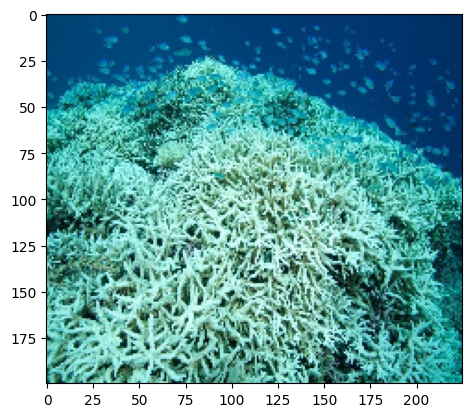

In [4]:
# Data inferencing using image from the internet

## Download the image

## Predict the image
image_inf, y_pred_class_name = prediction('inference_data.jpg')

## Show the prediction
plt.imshow(image_inf)
print('Prediction : ', y_pred_class_name)

Terlihat bahwa model telah berhasil mengklasifikasikan gambar baru sebagai `bleached_corals`